# CS336 TinyStories training in Colab

Train a small (22.7-million-parameter) decoder-only Transformer language model from random initialization, evaluate its ability to predict held-out text, and use it to complete new story prompts. This model is related to GPT-2, but it is not GPT-2 in the strict architectural sense. Both are autoregressive, decoder-only Transformers that predict the next token based on the preceding tokens.

This is the Colab track for the project: Stanford CS336 Assignment 1 on TinyStories, run end-to-end on a T4 GPU in Google Colab.

There is also an H100 track that trains a 124-million-parameter Llama model on FineWeb-Edu, with the code in `llama_lab/`. This larger model will be trained on H100 GPUs rented from Modal Labs.

[**Open in Colab**](https://colab.research.google.com/github/xqzr2000/Stanford-CS336-Llama-Adaptation/blob/main/CS336_Colab/CS336_TinyStories_Training.ipynb) · In Colab, select **Runtime → Change runtime type → T4 GPU**. Google Drive holds the prepared data, checkpoints, and exports, so separate sessions chain together. The raw training split is about 2.23 GB. Allow several GB of free space on Drive and in the runtime.

The learning-rate sweep is complete. This notebook now starts the full run at the selected peak learning rate of **`3e-3`**.

| Step | `MODE` | Profile | Tokens processed | Iterations at batch 32 × context 256 | Estimated T4 time |
|---|---|---|---:|---:|---:|
| 1 · Learning-rate sweep (completed) | `"sweep"` | `40m` | 40,960,000 per rate | 5,000 per rate | See Section 7 |
| 2 · Full run | `"train"` | `full` | 327,680,000 | 40,000 | about 2–4 h |
| 3 · Stories and packaging | `"generate"` or after training | — | — | — | minutes |

At the roughly 41,000 tokens/sec observed in the sweep, the full run would take about 2.2 hours for training alone. Validation and checkpoint writes add time. The training cell prints throughput and an ETA every 50 iterations.

Both profiles use the Assignment 1 TinyStories architecture and train on randomly sampled windows from the full training split. Each run has its own learning-rate schedule sized to its budget. The handout gives **1.45** as a validation-loss target for the tuned full run and **2.00** as a low-resource reference. 

Your execution results may vary depending on the tokenizer, evaluation sample, and training settings. Here are our training results (Nov-17-2026):

```text
Full validation split: loss 1.4099 | perplexity 4.10 | 5,441,280 target tokens
```

This self-study walkthrough uses Hugging Face's optimized byte-level BPE implementation to train a new tokenizer on the corpus. The model, cross-entropy, and AdamW are defined in the notebook. PyTorch supplies tensor operations, autograd, and mixed precision.

**References**

- [CS336 Assignment 1 handout](https://github.com/stanford-cs336/assignment1-basics/blob/main/cs336_assignment1_basics.pdf)
- [TinyStories dataset](https://huggingface.co/datasets/roneneldan/TinyStories)
- [PyTorch mixed precision](https://docs.pytorch.org/docs/stable/notes/amp_examples.html)
- [Folder README](https://github.com/xqzr2000/Stanford-CS336-Llama-Adaptation/tree/main/CS336_Colab)

## 0. Understanding the 101s

### TinyStories dataset

[**TinyStories**](https://arxiv.org/abs/2305.07759) is a synthetic dataset of short, simple stories created for training and evaluating small language models. The stories were generated using larger language models and are written with a relatively limited vocabulary and straightforward narrative structure.

The commonly used TinyStories training split contains approximately:

- **2.12 million training stories**
- **Approximately 22,000 validation stories**
- Around **500 million training tokens**, depending on the tokenizer and dataset version

The exact token count can vary because it depends on the dataset version, preprocessing, tokenizer vocabulary, and whether special tokens are included. Therefore, it is best to treat 500 million tokens as an approximate dataset size rather than an exact value.



### How TinyStories is used in this project

TinyStories supplies the text used to train the approximately **22.7-million-parameter decoder-only Transformer**. The stories are tokenized and converted into sequences of token IDs. During training, the model receives a sequence of tokens and learns to predict the next token at every position.

For example, a training sequence might look conceptually like this:

```text
The cat sat on the mat
```

The model is trained to make predictions such as:

```text
The → cat
cat → sat
sat → on
on → the
the → mat
```

In practice, the data is arranged into fixed-length sequences of 256 tokens. With a batch size of 32, each training iteration processes:

$$
32 \times 256 = 8{,}192 \text{ tokens}
$$

The training code typically samples batches of token sequences from the training split rather than processing one complete story per iteration. As a result, the number of stories in the dataset and the number of tokens processed by the experiment are related but not identical.

### How the profiles relate to the dataset

The learning-rate sweep uses a short subset of the available training budget:

- Each sweep run processes approximately **40.96 million tokens**.
- Three learning-rate runs process **122.88 million tokens in total**.
- These runs are used to compare learning rates, not to fully train the model.

The full run processes:

$$
40{,}000 \times 8{,}192
= 327{,}680{,}000 \text{ tokens}
$$

or approximately **328 million tokens**.

The cached training split in this notebook contains about 539 million token IDs. The full run processes a token budget equivalent to:

$$
\frac{327.68\text{M}}{538.82\text{M}} \approx 61\%
$$

of the corpus length. Randomly sampled windows can overlap, so the share of distinct tokens seen may be lower.

Later, during dataset preparation, we'll see some output like:

```text
Download train:2.23G

train: 538,816,658 token IDs
```

Therefore, the full run may process **less than one complete pass through the TinyStories training corpus**. This is not necessarily a problem: language-model training is usually organized around a token budget and randomly sampled batches, rather than requiring exactly one or more complete passes through every document.

The validation split is kept separate from training. The model does not update its parameters using validation stories. Instead, the validation data is used to measure how well the trained model predicts text it did not train on. This provides an estimate of generalization and helps identify overfitting.

### Relationship to the Chinchilla-style rule

A rough [Chinchilla-style](https://arxiv.org/abs/2203.15556) guideline is approximately **20 training tokens per model parameter** for compute-efficient training. For this project’s full run:

$$
\frac{327.68\text{M training tokens}}{22.696\text{M parameters}}
\approx 14.4 \text{ tokens per parameter}
$$

The full run uses about 14.4 training tokens per parameter.

However, the Chinchilla result is a scaling-law guideline, not a requirement that every model must follow exactly. It was derived from experiments involving much larger models and datasets. For this project, the ratio is best viewed as a useful reference point showing that the training budget is broadly proportional to the model size.

### Training schedule

| Step | `MODE` | Profile | Tokens processed | Iterations at batch 32 × context 256 | Estimated T4 time |
|---|---|---|---:|---:|---:|
| 1 · Learning-rate sweep (completed) | `"sweep"` | 40.96M tokens × 3 rates | 40,960,000 per rate | 5,000 per rate | About 40–90 minutes total |
| 2 · Full run | `"train"` | 327.68M tokens | 327,680,000 | 40,000 | About 2–4 hours |

**Key takeaway:** TinyStories provides the training and validation text. The model has about **22.7 million parameters**, and the profiles set how many tokens it processes. The full run processes about **14.4 tokens per parameter**.

## 1. Runtime and settings

- **`MODE = "train"`** is the default. Run from the top with `PROFILE = "full"` and `PEAK_LR = 3e-3`. The data cell reuses your saved tokenizer and token IDs. The final training cell starts or resumes the full run.
- **`MODE = "generate"`** loads a saved export. Drive is the default. A CPU runtime works. Use `GENERATE_FROM = "local"` for a manually downloaded and uploaded model, or `"github"` for the existing public-repo download path.
- **`MODE = "sweep"`** explicitly runs the sweep section. Keep `"train"` selected for the final run.

A blank `RUN_LABEL` uses the learning rate in the folder name, so the default final run uses `runs/full-lr3e-03`. Keep the same profile, learning rate, and label when reopening Colab to resume. Use one runtime per run folder.

`MAX_UPDATES_THIS_SESSION` can cap the iterations for a short check. The training checkpoint still follows the hourly timer. A short check that ends before its first hourly save starts over on the next run. Leave the cap at `None` to finish the full run.

`FAST_ATTENTION` selects PyTorch's scaled dot-product attention. Section 3 compares its output with the hand-written attention.


In [ ]:
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    installed_tokenizers = version("tokenizers")
except PackageNotFoundError:
    installed_tokenizers = None

if installed_tokenizers != "0.22.2":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tokenizers==0.22.2"])

In [ ]:
import hashlib
import json
import math
import pickle
import shutil
import tempfile
import time
from contextlib import nullcontext
from dataclasses import asdict, dataclass
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers
from torch import nn
from torch.nn import functional as F
from tqdm.auto import tqdm

MODE = "train"                      # "train", "generate", or "sweep"
PROFILE = "full"                   # MODE="train" and "generate": "40m" or "full"
PEAK_LR = 3e-3                     # MODE="train": set to the sweep's best rate
SWEEP_LRS = (3e-3, 5e-3, 7e-3)     # Only used when MODE="sweep"
RUN_LABEL = ""                     # Blank: named after the learning rate
MAX_UPDATES_THIS_SESSION = None    # e.g. 100 for a short first check
MICRO_BATCH_SIZE = 32
EFFECTIVE_BATCH_SIZE = 32
FAST_ATTENTION = False             # PyTorch's fused attention for training
USE_FP16 = True
SEED = 336
LOG_EVERY = 50
EVAL_EVERY = 250
CHECKPOINT_INTERVAL_SECONDS = 60 * 60
VAL_WINDOWS = 512                  # Fixed held-out windows for each check
GENERATE_FROM = "drive"            # "drive", "local", or "github"
LOCAL_MODEL_PATH = Path("/content/model.pt")

USE_DRIVE = True
DRIVE_ROOT = Path("/content/drive/MyDrive/CS336_TinyStories")
LOCAL_ROOT = Path("/content/cs336_tinystories")
GITHUB_MODEL_URL = ("https://raw.githubusercontent.com/xqzr2000/Stanford-CS336-Llama-Adaptation/"
                    "main/CS336_Colab/model.pt")

CONTEXT_LENGTH = 256
VOCAB_SIZE = 10_000
TARGET_TOKENS = {"40m": 40_960_000, "full": 327_680_000}
TOKENS_PER_UPDATE = EFFECTIVE_BATCH_SIZE * CONTEXT_LENGTH
ACCUM_STEPS = EFFECTIVE_BATCH_SIZE // MICRO_BATCH_SIZE

if MODE not in {"sweep", "train", "generate"} or PROFILE not in TARGET_TOKENS:
    raise ValueError("Choose a valid MODE and PROFILE.")
if GENERATE_FROM not in {"drive", "local", "github"}:
    raise ValueError('GENERATE_FROM must be "drive", "local", or "github".')
if RUN_LABEL and not all(c.isalnum() or c in "-_" for c in RUN_LABEL):
    raise ValueError("Use letters, numbers, hyphens, or underscores for RUN_LABEL.")
if not 0 < MICRO_BATCH_SIZE <= EFFECTIVE_BATCH_SIZE or EFFECTIVE_BATCH_SIZE % MICRO_BATCH_SIZE:
    raise ValueError("MICRO_BATCH_SIZE must divide EFFECTIVE_BATCH_SIZE.")
if min(LOG_EVERY, EVAL_EVERY, CHECKPOINT_INTERVAL_SECONDS, VAL_WINDOWS) < 1 or min(PEAK_LR, *SWEEP_LRS) <= 0:
    raise ValueError("Use positive intervals and learning rates.")
if MAX_UPDATES_THIS_SESSION is not None and MAX_UPDATES_THIS_SESSION < 1:
    raise ValueError("The session update limit must be positive.")
for name, tokens in TARGET_TOKENS.items():
    if tokens % TOKENS_PER_UPDATE:
        raise ValueError(f"The effective batch must divide the {name} token budget exactly.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRAINING = MODE in {"sweep", "train"}
if TRAINING and device.type != "cuda":
    raise RuntimeError("Select a GPU runtime in Colab before training.")
AMP = USE_FP16 and device.type == "cuda"

def lr_label(lr):
    return f"lr{lr:.0e}"

def run_directory(profile, peak_lr, label=""):
    return root / "runs" / f"{profile}-{label or lr_label(peak_lr)}"

if USE_DRIVE and (TRAINING or GENERATE_FROM == "drive"):
    from google.colab import drive
    drive.mount("/content/drive")
    root = DRIVE_ROOT
else:
    root = LOCAL_ROOT
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
if TRAINING:
    (root / "runs").mkdir(parents=True, exist_ok=True)

print(torch.cuda.get_device_name() if device.type == "cuda" else "CPU")
print(f"Precision: {'FP16 autocast with gradient scaling' if AMP else 'FP32'} | "
      f"attention: {'fused' if FAST_ATTENTION else 'hand-written'}")
if MODE == "sweep":
    print(f"Sweep: 40m × {len(SWEEP_LRS)} rates {[lr_label(lr) for lr in SWEEP_LRS]}")
elif MODE == "generate" and GENERATE_FROM == "github":
    print(f"generate: model.pt from {GITHUB_MODEL_URL}")
elif MODE == "generate" and GENERATE_FROM == "local":
    print(f"generate: {LOCAL_MODEL_PATH}")
else:
    print(f"{MODE}: {run_directory(PROFILE, PEAK_LR, RUN_LABEL)}")

Mounted at /content/drive
,Tesla T4
,Precision: FP16 autocast with gradient scaling | attention: hand-written
,train: /content/drive/MyDrive/CS336_TinyStories/runs/full-lr3e-03


## 2. Train the tokenizer and prepare token IDs

The course uses the GPT-4 version of TinyStories. The two raw text files mark story boundaries with `<|endoftext|>`. Byte-level BPE begins with a byte alphabet and learns merges of frequently adjacent symbols. We train the merges on the training split, then use that same tokenizer on the validation split. Each story contributes its text IDs and one end-of-story ID.

The first run downloads and encodes both splits. Later sessions reuse the token files on Drive and copy them to the Colab VM for fast random reads. Each token ID fits in an unsigned 16-bit integer, so the token files take two bytes per token.

The tokenizer and encoded splits are already saved by the sweep in `MyDrive/CS336_TinyStories/data/tinystories-f54c09fd-bytebpe10000-v1/`. The token streams take about **1.09 GB** combined. A fresh Colab runtime reads the existing `tokenizer.json` and stages the matching token files from Drive. If a cache file is missing, the cell builds the missing piece. Keep `DRIVE_ROOT` pointed at the folder used for the sweep.


In [ ]:
DATA_REVISION = "f54c09fd23315a6f9c86f9dc80f725de7d8f9c64"
DATA_URL = f"https://huggingface.co/datasets/roneneldan/TinyStories/resolve/{DATA_REVISION}"
DATA_NAME = "TinyStoriesV2-GPT4"
EOT = "<|endoftext|>"

def atomic_write(path, writer):
    # Publish a completed file under its final name.
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, prefix=f".{path.name}.", suffix=".part", delete=False) as f:
        partial = Path(f.name)
    try:
        writer(partial)
        partial.replace(path)
    finally:
        partial.unlink(missing_ok=True)

def stage_copy(source, destination):
    if source != destination:
        atomic_write(destination, lambda path: shutil.copyfile(source, path))

def download_split(split, destination):
    if destination.exists():
        return
    url = f"{DATA_URL}/{DATA_NAME}-{split}.txt"

    def download(path):
        with requests.get(url, stream=True, timeout=(30, 120)) as response:
            response.raise_for_status()
            size = int(response.headers.get("Content-Length", 0))
            with path.open("wb") as output, tqdm(
                total=size or None, unit="B", unit_scale=True, desc=f"Download {split}"
            ) as progress:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    output.write(chunk)
                    progress.update(len(chunk))
    atomic_write(destination, download)

def stories(path):
    lines = []
    with path.open(encoding="utf-8") as source:
        for line in source:
            if line.strip() == EOT:
                story = "".join(lines)
                if story.strip():
                    yield story
                lines.clear()
            else:
                lines.append(line)
    story = "".join(lines)
    if story.strip():
        yield story

def story_batches(path, size=2048):
    iterator = iter(stories(path))
    while batch := list(islice(iterator, size)):
        yield batch

def train_tokenizer(train_text):
    tokenizer = Tokenizer(models.BPE())
    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tokenizer.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=VOCAB_SIZE,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        special_tokens=[EOT],
    )
    tokenizer.train_from_iterator(story_batches(train_text), trainer=trainer)
    return tokenizer

def encode_split(tokenizer, raw_path, destination):
    eos_id = tokenizer.token_to_id(EOT)

    def write_tokens(path):
        with path.open("wb") as output:
            for batch in tqdm(story_batches(raw_path), desc=f"Encode {raw_path.stem}"):
                encodings = tokenizer.encode_batch(batch, add_special_tokens=False)
                ids = [token_id for encoding in encodings for token_id in (*encoding.ids, eos_id)]
                np.asarray(ids, dtype="<u2").tofile(output)
    atomic_write(destination, write_tokens)

### 2.1 Training a Byte-Level BPE Tokenizer

Before training our language model, we need to convert the TinyStories text dataset into numerical representations that a neural network can understand. We do this using **Byte-level Byte Pair Encoding (BPE)**, a subword tokenization algorithm.

#### What is BPE?

Byte Pair Encoding (BPE) is a subword tokenization algorithm that builds a vocabulary by repeatedly merging frequently occurring adjacent units.

Instead of treating every word as an independent token, BPE learns to represent text using frequently occurring character sequences and word fragments.

For example, consider these words:

- `playing`
- `played`
- `player`
- `plays`

A word-based tokenizer might treat all four as separate tokens. A BPE tokenizer can learn reusable subword units such as `play`, `ing`, `ed`, and `er`, allowing different words to share parts of their representation.

The basic BPE algorithm works as follows:

1. Start with a vocabulary consisting of individual symbols.
2. Count the frequency of adjacent symbol pairs across the training corpus.
3. Identify the most frequently occurring pair.
4. Merge that pair into a new token.
5. Repeat the process until the desired vocabulary size is reached.

Each merge creates a new token that can represent a more frequently occurring sequence of characters or bytes.

This allows the tokenizer to balance vocabulary size and sequence length: common sequences can be represented by a single token, while less common words can be represented by multiple smaller tokens.

#### Why Byte-Level BPE?

Our implementation uses Byte-level BPE rather than conventional character-level BPE.

The main difference is the initial representation of the text:

- Character-level BPE starts with individual characters.
- Byte-level BPE starts with individual bytes (values from 0 to 255).

This provides a universal starting vocabulary and allows the tokenizer to represent arbitrary text, including uncommon words, unusual characters, and different languages, without requiring an unknown-token fallback for unseen characters.

As frequent byte sequences are merged, the tokenizer gradually builds a vocabulary containing commonly occurring words, word fragments, and other text patterns.

#### How We Implemented It

We use the `Tokenizer` implementation from the Hugging Face Tokenizers library to train and apply our Byte-level BPE tokenizer.

Our implementation follows three main stages.

**Stage 1: Train the tokenizer**

We use the TinyStories training split (`train.txt`) to learn the vocabulary and BPE merge rules.

```python
tokenizer = train_tokenizer(raw_paths["train"])
```

The tokenizer learns which byte sequences frequently occur together and builds a vocabulary according to our configured `VOCAB_SIZE`.

Importantly, we train the tokenizer only on the training split. We do not use the validation data to construct the vocabulary, preventing information from the validation set from influencing tokenizer training.

Once trained, we serialize and save the tokenizer:

```python
tokenizer_json = tokenizer.to_str()

atomic_write(
    tokenizer_path,
    lambda path: path.write_text(
        tokenizer_json,
        encoding="utf-8"
    )
)
```

The resulting `tokenizer.json` contains the tokenizer configuration, vocabulary, and learned merge information. We can reload it in subsequent runs instead of training it again.

**Stage 2: Encode the datasets**

After training the tokenizer, we apply the same tokenizer to both training and validation datasets:

```python
encode_split(tokenizer, raw_path, local_file)
```

This converts the original text into sequences of integer token IDs.

For example, a sentence such as:

```text
Once upon a time, a little robot found a blue kite.
```

might become a sequence like:

```python
[1254, 318, 264, 892, 15, 264, 1732, 4211, ...]
```

These numbers are illustrative; the actual IDs depend on our trained vocabulary.

Using the same tokenizer for both datasets ensures that a given token always maps to the same integer ID.

**Stage 3: Save the encoded datasets**

Instead of repeatedly processing raw text during model training, we save the token IDs as binary files:

```text
train-{tokenizer_hash}.bin
valid-{tokenizer_hash}.bin
```

We store the IDs as unsigned 16-bit integers (`uint16`), which is sufficient for our configured vocabulary size.

We then use NumPy memory mapping to access the encoded data efficiently:

```python
streams[split] = np.memmap(
    local_file,
    dtype="<u2",
    mode="r"
)
```

This allows us to work with large datasets without loading the entire encoded dataset into memory.

#### Why This Matters for Language Model Training

The tokenizer establishes the interface between natural language and our neural network.

After preprocessing, the model no longer operates directly on words or characters. It operates on integer token IDs.

During training, the language model learns to predict the next token in a sequence:

$$
P(x_{t+1}\mid x_1,x_2,\ldots,x_t)
$$

Here, each \(x_t\) represents a token ID rather than a raw character or word.

The tokenizer therefore determines how text is segmented, how long the resulting token sequences are, and what vocabulary the model must learn to predict.

**In summary:** We use Byte-level BPE to learn a compact, reusable subword vocabulary from TinyStories. We train the tokenizer on the training split, apply it consistently to both training and validation data, and store the resulting token IDs in binary format for efficient language model training.

In [ ]:
if TRAINING:
    data_key = f"tinystories-{DATA_REVISION[:8]}-bytebpe{VOCAB_SIZE}-v1"
    cache_dir = root / "data" / data_key
    work_dir = LOCAL_ROOT / "data" / data_key
    raw_paths = {split: work_dir / f"{split}.txt" for split in ("train", "valid")}
    tokenizer_path = cache_dir / "tokenizer.json"

    if tokenizer_path.exists():
        tokenizer_json = tokenizer_path.read_text(encoding="utf-8")
        tokenizer = Tokenizer.from_str(tokenizer_json)
        print(f"Loaded cached BPE tokenizer: {tokenizer_path}")
    else:
        print("Training BPE tokenizer for the initial data cache.")
        download_split("train", raw_paths["train"])
        tokenizer = train_tokenizer(raw_paths["train"])
        tokenizer_json = tokenizer.to_str()
        atomic_write(tokenizer_path, lambda path: path.write_text(tokenizer_json, encoding="utf-8"))

    tokenizer_hash = hashlib.sha256(tokenizer_json.encode("utf-8")).hexdigest()
    if tokenizer.get_vocab_size() != VOCAB_SIZE or tokenizer.token_to_id(EOT) is None:
        raise ValueError("The cached tokenizer has the wrong vocabulary or is missing the story marker.")

    streams = {}
    for split, raw_path in raw_paths.items():
        name = f"{split}-{tokenizer_hash[:16]}.bin"
        cached_file = cache_dir / name
        local_file = work_dir / name
        if not cached_file.exists():
            download_split(split, raw_path)
            encode_split(tokenizer, raw_path, local_file)
            stage_copy(local_file, cached_file)
            print(f"Saved {split} token IDs to Drive cache: {cached_file}")
        else:
            if not local_file.exists() or local_file.stat().st_size != cached_file.stat().st_size:
                stage_copy(cached_file, local_file)
            print(f"Loaded cached {split} token IDs: {cached_file}")
        streams[split] = np.memmap(local_file, dtype="<u2", mode="r")
        print(f"{split}: {len(streams[split]):,} token IDs")

    example = "Once upon a time, a little robot found a blue kite."
    encoded = tokenizer.encode(example)
    print(encoded.tokens)
    print(encoded.ids)
    assert tokenizer.decode(encoded.ids) == example

Loaded cached BPE tokenizer: /content/drive/MyDrive/CS336_TinyStories/data/tinystories-f54c09fd-bytebpe10000-v1/tokenizer.json
,Loaded cached train token IDs: /content/drive/MyDrive/CS336_TinyStories/data/tinystories-f54c09fd-bytebpe10000-v1/train-0c0428d24956aac3.bin
,train: 538,816,658 token IDs
,Loaded cached valid token IDs: /content/drive/MyDrive/CS336_TinyStories/data/tinystories-f54c09fd-bytebpe10000-v1/valid-0c0428d24956aac3.bin
,valid: 5,441,295 token IDs
,['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġa', 'Ġlittle', 'Ġrobot', 'Ġfound', 'Ġa', 'Ġblue', 'Ġkite', '.']
,[430, 439, 259, 398, 12, 259, 390, 2050, 505, 259, 925, 1912, 14]


## 3. Build the Transformer

A batch of token IDs has shape $[B,T]$. The embedding maps it to $[B,T,D]$. Each pre-norm residual block uses RMSNorm, causal multi-head attention, and a SwiGLU feed-forward layer. The output projection produces $[B,T,V]$ logits, where $V$ is the vocabulary size.

- **RMSNorm** divides by the root mean square across features, then multiplies by a learned scale: $\operatorname{RMSNorm}(x)_i = g_i\,x_i\big/\sqrt{\tfrac{1}{D}\sum_j x_j^2+\epsilon}$.
- **RoPE** rotates the queries and keys in feature pairs by angles that depend on position. The dot product then depends on the relative rotation between positions.
- **Causal attention** scores each query against every key, $S=QK^\top/\sqrt{d_h}$. The mask removes future keys before softmax, and the output is $\operatorname{softmax}(S)\,V$ for each head.
- **SwiGLU** computes $\operatorname{SiLU}(xW_1)\odot(xW_3)$ before projecting back to model width with $W_2$.

The default model has 4 layers, width 512, 16 query/key/value heads, feed-forward width 1,344, and separate input embeddings and output weights: 22,696,448 parameters.

With `FAST_ATTENTION = True`, the attention layer calls `F.scaled_dot_product_attention(q, k, v, is_causal=True)` on the same rotated queries and keys. It computes the same equation without storing the full $T\times T$ score matrix in memory, which is the slowest part of the hand-written version on a T4. The next cells define the model and check that both paths agree.

In [ ]:
@dataclass(frozen=True)
class ModelConfig:
    vocab_size: int = 10_000
    context_length: int = 256
    width: int = 512
    heads: int = 16
    layers: int = 4
    ff_width: int = 1344
    rope_theta: float = 10_000.0

class Linear(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(out_features, in_features))
        std = math.sqrt(2 / (in_features + out_features))
        nn.init.trunc_normal_(self.weight, std=std, a=-3 * std, b=3 * std)

    def forward(self, x):
        return x @ self.weight.T

class RMSNorm(nn.Module):
    def __init__(self, width, eps=1e-5):
        super().__init__()
        self.scale = nn.Parameter(torch.ones(width))
        self.eps = eps

    def forward(self, x):
        xf = x.float()
        normalized = xf * torch.rsqrt(xf.square().mean(dim=-1, keepdim=True) + self.eps)
        return (normalized * self.scale).to(x.dtype)

class RotaryEmbedding(nn.Module):
    def __init__(self, length, head_dim, theta):
        super().__init__()
        inverse_frequency = theta ** (-torch.arange(0, head_dim, 2).float() / head_dim)
        angles = torch.outer(torch.arange(length).float(), inverse_frequency)
        self.register_buffer("cos", angles.cos(), persistent=False)
        self.register_buffer("sin", angles.sin(), persistent=False)

    def forward(self, x):
        length = x.size(-2)
        cos = self.cos[:length].to(x.dtype)
        sin = self.sin[:length].to(x.dtype)
        even, odd = x[..., 0::2], x[..., 1::2]
        return torch.stack((even * cos - odd * sin, odd * cos + even * sin), dim=-1).flatten(-2)

class CausalAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.heads = config.heads
        self.head_dim = config.width // config.heads
        self.query = Linear(config.width, config.width)
        self.key = Linear(config.width, config.width)
        self.value = Linear(config.width, config.width)
        self.output = Linear(config.width, config.width)
        self.rope = RotaryEmbedding(config.context_length, self.head_dim, config.rope_theta)
        future = torch.ones(config.context_length, config.context_length, dtype=torch.bool).triu(1)
        self.register_buffer("future", future, persistent=False)

    fast = False  # Set from FAST_ATTENTION below.

    def forward(self, x):
        batch, length, width = x.shape

        def split_heads(z):
            return z.reshape(batch, length, self.heads, self.head_dim).transpose(1, 2)

        q = self.rope(split_heads(self.query(x)))
        k = self.rope(split_heads(self.key(x)))
        v = split_heads(self.value(x))
        if self.fast:
            combined = F.scaled_dot_product_attention(q, k, v, is_causal=True)
            return self.output(combined.transpose(1, 2).reshape(batch, length, width))
        scores = (q @ k.transpose(-1, -2)).float() / math.sqrt(self.head_dim)
        scores = scores.masked_fill(self.future[:length, :length], -torch.inf)
        attention = scores.softmax(dim=-1).to(v.dtype)
        combined = (attention @ v).transpose(1, 2).reshape(batch, length, width)
        return self.output(combined)

class SwiGLU(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.gate = Linear(config.width, config.ff_width)
        self.up = Linear(config.width, config.ff_width)
        self.down = Linear(config.ff_width, config.width)

    def forward(self, x):
        gate = self.gate(x)
        return self.down((gate * gate.sigmoid()) * self.up(x))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.attn_norm = RMSNorm(config.width)
        self.attention = CausalAttention(config)
        self.ff_norm = RMSNorm(config.width)
        self.ff = SwiGLU(config)

    def forward(self, x):
        x = x + self.attention(self.attn_norm(x))
        return x + self.ff(self.ff_norm(x))

class TinyStoriesLM(nn.Module):
    def __init__(self, config):
        super().__init__()
        if config.width % (2 * config.heads):
            raise ValueError("The attention head dimension must be an even integer for RoPE.")
        self.config = config
        self.embedding = nn.Parameter(torch.empty(config.vocab_size, config.width))
        nn.init.trunc_normal_(self.embedding, std=1.0, a=-3.0, b=3.0)
        self.blocks = nn.ModuleList(Block(config) for _ in range(config.layers))
        self.norm = RMSNorm(config.width)
        self.lm_head = Linear(config.width, config.vocab_size)

    def forward(self, token_ids):
        if not 1 <= token_ids.size(1) <= self.config.context_length:
            raise ValueError("Sequence length is outside the model context.")
        x = self.embedding[token_ids]
        for block in self.blocks:
            x = block(x)
        return self.lm_head(self.norm(x))

CausalAttention.fast = FAST_ATTENTION

In [ ]:
# Both attention paths on the same small model and input.
check_config = ModelConfig(vocab_size=64, context_length=32, width=64, heads=4, layers=2, ff_width=128)
torch.manual_seed(SEED)
check_model = TinyStoriesLM(check_config).to(device).eval()
check_ids = torch.randint(0, 64, (2, 32), device=device)
outputs = {}
with torch.inference_mode():
    for fast in (False, True):
        CausalAttention.fast = fast
        outputs[fast] = check_model(check_ids).float()
CausalAttention.fast = FAST_ATTENTION
torch.testing.assert_close(outputs[True], outputs[False], atol=1e-4, rtol=1e-4)
print(f"Fused and hand-written attention agree in FP32 on {device}.")
if device.type == "cuda":
    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):
        CausalAttention.fast = False
        slow = check_model(check_ids).float()
        CausalAttention.fast = True
        fast = check_model(check_ids).float()
    CausalAttention.fast = FAST_ATTENTION
    print(f"Largest FP16 logit difference: {(fast - slow).abs().max().item():.1e}")
del check_model

Fused and hand-written attention agree in FP32 on cuda.
,Largest FP16 logit difference: 2.1e-03


## 4. Predict the next token

A window of $T+1$ IDs gives $T$ input IDs and $T$ targets shifted one position forward. For target ID $y$ and vocabulary logits $z$, the loss is $\log\sum_j e^{z_j}-z_y$. We compute the reduction in FP32 and average over all positions. Perplexity is $e^{\text{validation loss}}$.

Validation during training uses the same `VAL_WINDOWS` randomly selected windows at each check, so checkpoints are compared on identical text. When a run finishes, the notebook also scores the **entire** validation split in non-overlapping windows and stores that number as the run's final result.

The optimizer is AdamW. It keeps exponential moving averages $m$ and $v$ of the gradients and of their squares, corrects their initialization bias, and applies weight decay separately from the gradient update:

$$
\theta \leftarrow \theta(1-\eta\lambda) - \eta\,\frac{m/(1-\beta_1^t)}{\sqrt{v/(1-\beta_2^t)}+\epsilon}.
$$

The learning rate warms up linearly over the first 5% of iterations, then follows a cosine down to 10% of the peak:

$$
\eta(s)=\begin{cases}\eta_{\max}\,s/W & s\le W\\[4pt] \eta_{\max}\big[0.1+0.45\,(1+\cos(\pi\,\tfrac{s-W}{S-W}))\big] & s>W.\end{cases}
$$

Run the following cell to define batching, loss, AdamW, the schedule, and validation.

In [ ]:
def next_token_batch(stream, batch_size, context, generator):
    if len(stream) <= context:
        raise ValueError("The token stream is shorter than one training window.")
    starts = torch.randint(len(stream) - context, (batch_size,), generator=generator).numpy()
    indices = starts[:, None] + np.arange(context + 1)
    windows = torch.from_numpy(stream[indices].astype(np.int64)).to(device)
    return windows[:, :-1], windows[:, 1:]

def next_token_loss(logits, targets):
    logits = logits.float()
    selected = logits.gather(-1, targets.unsqueeze(-1)).squeeze(-1)
    return (torch.logsumexp(logits, dim=-1) - selected).mean()

class AdamW(torch.optim.Optimizer):
    def __init__(self, parameters, lr, betas=(0.9, 0.95), eps=1e-8, weight_decay=0.1):
        super().__init__(parameters, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr, (beta1, beta2) = group["lr"], group["betas"]
            for parameter in group["params"]:
                grad = parameter.grad
                if grad is None:
                    continue
                state = self.state[parameter]
                if not state:
                    state["step"] = 0
                    state["mean"] = torch.zeros_like(parameter)
                    state["square_mean"] = torch.zeros_like(parameter)
                state["step"] += 1
                step = state["step"]
                mean, square_mean = state["mean"], state["square_mean"]
                mean.lerp_(grad, 1 - beta1)
                square_mean.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
                denominator = square_mean.sqrt().div_(math.sqrt(1 - beta2 ** step))
                denominator.add_(group["eps"])
                parameter.mul_(1 - lr * group["weight_decay"])
                parameter.addcdiv_(mean, denominator, value=-lr / (1 - beta1 ** step))

def learning_rate(step, total_steps, peak_lr):
    warmup = max(1, int(total_steps * 0.05))
    if step <= warmup:
        return peak_lr * step / warmup
    progress = (step - warmup) / (total_steps - warmup)
    return peak_lr * (0.1 + 0.45 * (1 + math.cos(math.pi * progress)))

def mixed_precision():
    return torch.autocast("cuda", dtype=torch.float16) if AMP else nullcontext()

@torch.inference_mode()
def validation_loss(model, stream):
    """Mean loss on VAL_WINDOWS fixed random windows."""
    model.eval()
    context = model.config.context_length
    generator = torch.Generator().manual_seed(SEED + 2)
    # Draw every start at once so the windows don't depend on MICRO_BATCH_SIZE.
    all_starts = torch.randint(len(stream) - context, (VAL_WINDOWS,), generator=generator).numpy()
    losses = []
    for first in range(0, VAL_WINDOWS, MICRO_BATCH_SIZE):
        starts = all_starts[first:first + MICRO_BATCH_SIZE]
        ids = torch.from_numpy(stream[starts[:, None] + np.arange(context + 1)].astype(np.int64)).to(device)
        with mixed_precision():
            losses.append(next_token_loss(model(ids[:, :-1]), ids[:, 1:]) * len(starts))
    model.train()
    return (torch.stack(losses).sum() / VAL_WINDOWS).item()

@torch.inference_mode()
def full_validation_loss(model, stream, batch_size=64):
    """Mean loss over the whole validation split in non-overlapping windows."""
    model.eval()
    context = model.config.context_length
    windows = (len(stream) - 1) // context
    total = torch.zeros((), device=device, dtype=torch.float64)
    for first in range(0, windows, batch_size):
        starts = np.arange(first, min(first + batch_size, windows)) * context
        indices = starts[:, None] + np.arange(context + 1)
        ids = torch.from_numpy(stream[indices].astype(np.int64)).to(device)
        with mixed_precision():
            total += next_token_loss(model(ids[:, :-1]), ids[:, 1:]).double() * len(starts)
    model.train()
    return (total / windows).item(), windows * context

## 5. Save and resume

Training writes a checkpoint after each hour of elapsed time in the training loop, including validation. The timer restarts after a successful save. The run keeps the latest two checkpoints, about **545 MB** combined, and tries the older one if the newest is unreadable. Each file restores the model in FP32, AdamW state, gradient scaler, sampler, and training history.

After a disconnect, run from the top with the same settings. The notebook resumes after the latest saved iteration. Any later work is replayed. If Colab disconnects before the first hourly checkpoint, training starts again at iteration 1. The retention policy applies to this run folder. Earlier sweep folders and their files can be reviewed separately in Drive. 

[Google Drive Trash and storage](https://support.google.com/drive/answer/2375102)

At completion, the notebook writes **`model.pt`** with FP16 weights, configuration, tokenizer, and validation results. It is about **46 MB** and loads into an FP32 model for the demo. `metrics.json` saves settings and training and validation history.


In [ ]:
def save_torch(payload, destination):
    # Serialize on the VM disk first, then copy to the destination.
    with tempfile.TemporaryDirectory(dir=LOCAL_ROOT) as directory:
        local_file = Path(directory) / destination.name
        torch.save(payload, local_file)
        stage_copy(local_file, destination)

def write_metrics(run_dir, spec, history, **extra):
    payload = {"run": run_dir.name, "spec": spec, "history": history, **extra}
    atomic_write(run_dir / "metrics.json",
                 lambda path: path.write_text(json.dumps(payload, indent=1), encoding="utf-8"))

def checkpoint_paths(run_dir):
    pattern = "checkpoint-" + "[0-9]" * 8 + ".pt"
    return sorted(run_dir.glob(pattern), reverse=True)

def prune_checkpoints(run_dir):
    for old in checkpoint_paths(run_dir)[2:]:
        old.unlink(missing_ok=True)

def save_checkpoint(run_dir, model, optimizer, scaler, sampler, spec, step, history):
    destination = run_dir / f"checkpoint-{step:08d}.pt"
    save_torch({
        "spec": spec,
        "step": step,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "sampler": sampler.get_state(),
        "history": history,
    }, destination)
    prune_checkpoints(run_dir)
    write_metrics(run_dir, spec, history)
    print(f"Saved {destination.name}")

def resume_training(run_dir, model, optimizer, scaler, sampler, spec):
    checkpoints = checkpoint_paths(run_dir)
    if not checkpoints:
        return 0, []
    unreadable = []
    for checkpoint in checkpoints:
        try:
            state = torch.load(checkpoint, map_location="cpu", weights_only=True)
        except (OSError, RuntimeError, EOFError, IndexError, pickle.UnpicklingError) as error:
            print(f"Could not read {checkpoint.name} ({type(error).__name__}).")
            unreadable.append(checkpoint)
            continue
        if state["spec"] != spec:
            raise ValueError("Saved training settings differ. Restore those settings or use a new RUN_LABEL.")
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"])
        sampler.set_state(state["sampler"])
        for path in unreadable:
            path.unlink(missing_ok=True)
        prune_checkpoints(run_dir)
        print(f"Resuming after iteration {state['step']:,}")
        return state["step"], state["history"]
    raise RuntimeError("No readable checkpoint found. Inspect the saved files before starting a new run.")

def export_model(run_dir, model, tokenizer_json, spec, step, loss, full_loss, history):
    destination = run_dir / "model.pt"
    save_torch({
        "format_version": 2,
        "config": asdict(model.config),
        "model": {name: value.detach().cpu().half() for name, value in model.state_dict().items()},
        "tokenizer_json": tokenizer_json,
        "step": step,
        "total_steps": spec["total_steps"],
        "training_spec": spec,
        "history": history,
        "validation_loss": loss,
        "full_validation_loss": full_loss,
        "run": run_dir.name,
    }, destination)
    print(f"Inference export: {destination} ({destination.stat().st_size / 1e6:.1f} MB)")

def load_export(path):
    saved = torch.load(path, map_location="cpu", weights_only=True)
    if saved["format_version"] not in (1, 2):
        raise ValueError("This model export uses a different format version.")
    tokenizer = Tokenizer.from_str(saved["tokenizer_json"])
    model = TinyStoriesLM(ModelConfig(**saved["config"]))
    model.load_state_dict({name: value.float() for name, value in saved["model"].items()})
    return model.to(device).eval(), tokenizer, saved


def completed_history(run_dir, spec):
    """Identify a completed run from its final export, including older exports."""
    path = run_dir / "model.pt"
    if not path.is_file():
        return None
    try:
        export = torch.load(path, map_location="cpu", weights_only=True)
    except (OSError, RuntimeError, EOFError, IndexError, pickle.UnpicklingError) as error:
        print(f"Could not read {path.name} ({type(error).__name__}). Checking checkpoints.")
        return None
    if export["step"] != spec["total_steps"] or export.get("total_steps") != spec["total_steps"]:
        return None
    if "training_spec" in export:
        export_spec = export["training_spec"]
        history = export["history"]
    else:
        metrics_path = run_dir / "metrics.json"
        if not metrics_path.is_file():
            return None
        metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
        if not metrics.get("finished"):
            return None
        export_spec = metrics["spec"]
        history = metrics["history"]
    if export_spec != spec:
        raise ValueError("Saved training settings differ. Restore those settings or use a new RUN_LABEL.")
    if "training_spec" in export:
        # Recover metrics if a disconnect happened after the final export was written.
        write_metrics(run_dir, export_spec, history, finished=True, final_step=export["step"],
                      full_validation_loss=export["full_validation_loss"])
    return history


## 6. Train on the T4

The default batch is 32 sequences in a single pass, so each optimizer update averages the loss over 32 × 256 target positions. A smaller `MICRO_BATCH_SIZE` accumulates gradients over several passes: each micro-batch loss is divided by the number of passes, so the accumulated gradient is still an average over all 32 sequences. We keep the model and optimizer state in FP32, use FP16 autocast for eligible GPU operations, and unscale gradients before clipping them. The scaler can skip an optimizer update if the gradients overflow. The iteration and token counters still include that batch.

Use the steady-state tokens per second and the ETA printed here to plan your Colab time. The ETA covers training operations and excludes validation and checkpoint writes. A run that reaches its last iteration scores the whole validation split, about a minute on a T4, and exports `model.pt`. The cell below defines training. Section 8 starts it with the selected learning rate.

In [ ]:
def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()

def train(profile, peak_lr, label=""):
    """Train or resume one run and return its directory and history."""
    run_dir = run_directory(profile, peak_lr, label)
    run_dir.mkdir(parents=True, exist_ok=True)
    total_updates = TARGET_TOKENS[profile] // TOKENS_PER_UPDATE
    torch.manual_seed(SEED)
    sampler = torch.Generator().manual_seed(SEED + 1)
    config = ModelConfig(vocab_size=VOCAB_SIZE, context_length=CONTEXT_LENGTH)
    spec = {
        "config": asdict(config),
        "data_revision": DATA_REVISION,
        "tokenizer_hash": tokenizer_hash,
        "effective_batch": EFFECTIVE_BATCH_SIZE,
        "total_steps": total_updates,
        "peak_lr": peak_lr,
        "seed": SEED,
        "fp16": AMP,
        "val_windows": VAL_WINDOWS,
    }
    # Remove incomplete copies left by an interrupted transfer in this run folder.
    for pattern in (".checkpoint-*.pt.*.part", ".model.pt.*.part", ".metrics.json.*.part"):
        for partial in run_dir.glob(pattern):
            partial.unlink(missing_ok=True)

    history = completed_history(run_dir, spec)
    if history is not None:
        print(f"{run_dir.name} already finished at {total_updates:,} iterations.")
        return run_dir, history

    model = TinyStoriesLM(config).to(device)
    print(f"{run_dir.name}: {total_updates:,} iterations | "
          f"{sum(p.numel() for p in model.parameters()):,} parameters")
    optimizer = AdamW(model.parameters(), lr=peak_lr)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)

    start_step, history = resume_training(run_dir, model, optimizer, scaler, sampler, spec)
    final_step = min(total_updates, start_step + (MAX_UPDATES_THIS_SESSION or total_updates))
    last_val = next((row["val_loss"] for row in reversed(history) if "val_loss" in row), None)
    model.train()

    interval_steps = 0
    interval_seconds = 0.0
    interval_loss = torch.zeros((), device=device)
    block_start = time.perf_counter()
    next_checkpoint_at = time.monotonic() + CHECKPOINT_INTERVAL_SECONDS

    for step in range(start_step + 1, final_step + 1):
        lr = learning_rate(step, total_updates, peak_lr)
        for group in optimizer.param_groups:
            group["lr"] = lr
        optimizer.zero_grad(set_to_none=True)
        for _ in range(ACCUM_STEPS):
            x, y = next_token_batch(streams["train"], MICRO_BATCH_SIZE, config.context_length, sampler)
            with mixed_precision():
                loss = next_token_loss(model(x), y) / ACCUM_STEPS
            scaler.scale(loss).backward()
            interval_loss += loss.detach()
        scaler.unscale_(optimizer)
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        if not AMP and not torch.isfinite(grad_norm):
            raise FloatingPointError("Gradient norm is non-finite. Lower the learning rate.")
        scaler.step(optimizer)
        scaler.update()
        interval_steps += 1

        should_log = step % LOG_EVERY == 0 or step == final_step
        should_eval = step % EVAL_EVERY == 0 or step == final_step
        should_save = time.monotonic() >= next_checkpoint_at
        if should_log or should_eval or should_save:
            synchronize()
            interval_seconds += time.perf_counter() - block_start
        if should_log:
            mean_loss = interval_loss.item() / interval_steps
            if not math.isfinite(mean_loss):
                raise FloatingPointError("Training loss is non-finite. Check precision and learning rate.")
            rate = interval_steps * TOKENS_PER_UPDATE / interval_seconds
            eta_hours = (total_updates - step) * TOKENS_PER_UPDATE / rate / 3600
            print(f"{step:,}/{total_updates:,} | loss {mean_loss:.3f} | lr {lr:.2e} | "
                  f"{rate:,.0f} tok/s | ETA {eta_hours:.2f} h")
            history.append(dict(step=step, train_loss=mean_loss, tokens_per_second=rate))
            interval_loss.zero_()
            interval_steps, interval_seconds = 0, 0.0
        if should_eval:
            last_val = validation_loss(model, streams["valid"])
            if not math.isfinite(last_val):
                raise FloatingPointError("Validation loss is non-finite.")
            history.append(dict(step=step, val_loss=last_val))
            print(f"Validation loss {last_val:.3f} | perplexity {math.exp(last_val):.2f}")
        if should_save:
            save_checkpoint(run_dir, model, optimizer, scaler, sampler, spec, step, history)
            next_checkpoint_at = time.monotonic() + CHECKPOINT_INTERVAL_SECONDS
        if should_log or should_eval or should_save:
            block_start = time.perf_counter()

    if final_step < total_updates:
        checkpoints = checkpoint_paths(run_dir)
        last_saved = checkpoints[0].name if checkpoints else "none yet"
        print(f"Paused at iteration {final_step:,}. Latest hourly checkpoint: {last_saved}.")
        return run_dir, history

    full_loss, scored = full_validation_loss(model, streams["valid"], batch_size=MICRO_BATCH_SIZE)
    if not math.isfinite(full_loss):
        raise FloatingPointError("Full validation loss is non-finite.")
    print(f"Full validation split: loss {full_loss:.4f} | perplexity {math.exp(full_loss):.2f} | "
          f"{scored:,} target tokens")
    export_model(run_dir, model, tokenizer_json, spec, total_updates, last_val, full_loss, history)
    write_metrics(run_dir, spec, history, finished=True, final_step=total_updates,
                  full_validation_loss=full_loss)
    return run_dir, history


## 7. Completed learning-rate sweep on the 40m profile

The peak learning rate matters more than anything else in this notebook for reaching the handout's targets. Each rate in `SWEEP_LRS` trains a fresh `40m` run with the same seed, data order, and schedule shape, so the only difference is $\eta_{\max}$. A rate that diverges stops with a non-finite loss and is reported as such.

The saved cell output records the second sweep. The results below combine both rounds. With the default `MODE = "train"`, execution proceeds to Section 8. An explicitly selected sweep writes `lr_sweep.json` and `lr_sweep.png`.

In [ ]:
def summarize_sweep():
    rows = []
    for lr in SWEEP_LRS:
        metrics_path = run_directory("40m", lr) / "metrics.json"
        if not metrics_path.exists():
            continue
        metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
        checks = [row for row in metrics["history"] if "val_loss" in row]
        rows.append(dict(
            peak_lr=lr, finished=metrics.get("finished", False), diverged=metrics.get("diverged", False),
            last_step=checks[-1]["step"] if checks else 0,
            val_loss=checks[-1]["val_loss"] if checks else None,
            full_validation_loss=metrics.get("full_validation_loss"), history=checks,
        ))
    return rows

if MODE == "sweep":
    for lr in SWEEP_LRS:
        previous = run_directory("40m", lr) / "metrics.json"
        if previous.exists() and json.loads(previous.read_text()).get("diverged"):
            print(f"{lr_label(lr)} diverged in an earlier session. Skipping it.")
            continue
        try:
            train("40m", lr)
        except FloatingPointError as error:
            print(f"{lr_label(lr)} diverged: {error}")
            run_dir = run_directory("40m", lr)
            metrics = json.loads((run_dir / "metrics.json").read_text()) if (run_dir / "metrics.json").exists() else {}
            write_metrics(run_dir, metrics.get("spec"), metrics.get("history", []), diverged=True, finished=False)

    sweep = summarize_sweep()
    print(f"\n{'peak LR':>9} {'status':>10} {'last step':>10} {'sampled val':>12} {'full val':>9}")
    for row in sweep:
        status = "diverged" if row["diverged"] else "finished" if row["finished"] else "partial"
        sampled = f"{row['val_loss']:.4f}" if row["val_loss"] is not None else "—"
        full = f"{row['full_validation_loss']:.4f}" if row["full_validation_loss"] is not None else "—"
        print(f"{row['peak_lr']:>9.0e} {status:>10} {row['last_step']:>10,} {sampled:>12} {full:>9}")
    finished = [row for row in sweep if row["finished"] and row["full_validation_loss"] is not None]
    if finished:
        best = min(finished, key=lambda row: row["full_validation_loss"])
        print(f"\nBest rate: {best['peak_lr']:.0e} (full validation loss {best['full_validation_loss']:.4f}). "
              f"Set PEAK_LR = {best['peak_lr']:.0e} and MODE = \"train\" for the full run.")
        if best["peak_lr"] == max(SWEEP_LRS):
            print("The best rate is the largest one tried. Consider adding a higher rate to SWEEP_LRS.")

    fig, ax = plt.subplots(figsize=(9, 4))
    for row in sweep:
        ax.plot([r["step"] * TOKENS_PER_UPDATE / 1e6 for r in row["history"]],
                [r["val_loss"] for r in row["history"]], marker="o", markersize=3,
                label=f"{row['peak_lr']:.0e}" + (" (diverged)" if row["diverged"] else ""))
    ax.axhline(2.00, color="gray", linestyle="--", linewidth=1, label="handout 40M reference (2.00)")
    ax.set(xlabel="Training tokens processed (millions)", ylabel="Validation loss", title="40m learning-rate sweep")
    ax.grid(alpha=0.25)
    ax.legend(title="peak LR")
    sweep_png = root / "runs" / "lr_sweep.png"
    atomic_write(sweep_png, lambda path: fig.savefig(path, format="png", dpi=150, bbox_inches="tight"))
    atomic_write(root / "runs" / "lr_sweep.json",
                 lambda path: path.write_text(json.dumps(sweep, indent=1), encoding="utf-8"))
    plt.show()

### 7.1 Learning-Rate Sweep Results

You can adapt the code in this notebook to evaluate five peak learning rates: `[3e-4, 1e-3, 3e-3, 5e-3, 7e-3]`. We ran this sweep to identify the best-performing learning rate.

Because the saved checkpoints require substantial Google Drive storage, we divided the sweep into two rounds. After recording the validation losses from the first round, we cleared space in Google Drive and ran the second round, using the best learning rate from the first round as a reference:

1. `[3e-4, 1e-3, 3e-3]`
2. `[3e-3, 5e-3, 7e-3]`

The final comparison is shown below:

| Peak learning rate | Sampled validation loss | Full validation loss | Status |
|---:|---:|---:|---|
| $3 \times 10^{-4}$ | 1.9418 | 1.8831 | Finished |
| $1 \times 10^{-3}$ | 1.7303 | 1.6774 | Finished |
| $3 \times 10^{-3}$ | 1.7035 | **1.6544** | Finished |
| $5 \times 10^{-3}$ | 1.8117 | 1.7569 | Finished |
| $7 \times 10^{-3}$ | 1.8797 | 1.8271 | Finished |

The lowest full-validation-split loss was **1.6544**, achieved with a peak learning rate of `3e-3`. Section 8 uses this learning rate for a fresh full-budget run with a new learning-rate schedule configured for 40,000 iterations. The result reported above is from the sweep and not from the full-budget run.

## 8. Train the full profile

The defaults are ready for the full run. Select a T4 in Colab and run from the top. Expect several hours of training and use the ETA from the training log. If Colab disconnects, reopen this notebook and run from the top again with the same settings. The final export will be saved under `MyDrive/CS336_TinyStories/runs/full-lr3e-03/model.pt`.


In [ ]:
if MODE == "train":
    run_dir, history = train(PROFILE, PEAK_LR, RUN_LABEL)

full-lr3e-03: 40,000 iterations | 22,696,448 parameters
,50/40,000 | loss 8.565 | lr 7.50e-05 | 42,084 tok/s | ETA 2.16 h
,100/40,000 | loss 6.213 | lr 1.50e-04 | 44,657 tok/s | ETA 2.03 h
,150/40,000 | loss 4.547 | lr 2.25e-04 | 44,482 tok/s | ETA 2.04 h
,200/40,000 | loss 3.823 | lr 3.00e-04 | 43,168 tok/s | ETA 2.10 h
,250/40,000 | loss 3.475 | lr 3.75e-04 | 43,868 tok/s | ETA 2.06 h
,Validation loss 3.393 | perplexity 29.75
,300/40,000 | loss 3.216 | lr 4.50e-04 | 43,557 tok/s | ETA 2.07 h
,350/40,000 | loss 3.071 | lr 5.25e-04 | 43,195 tok/s | ETA 2.09 h
,400/40,000 | loss 2.947 | lr 6.00e-04 | 42,826 tok/s | ETA 2.10 h
,450/40,000 | loss 2.846 | lr 6.75e-04 | 42,428 tok/s | ETA 2.12 h
,500/40,000 | loss 2.740 | lr 7.50e-04 | 42,236 tok/s | ETA 2.13 h
,Validation loss 2.763 | perplexity 15.84
,550/40,000 | loss 2.665 | lr 8.25e-04 | 42,581 tok/s | ETA 2.11 h
,600/40,000 | loss 2.614 | lr 9.00e-04 | 42,979 tok/s | ETA 2.09 h
,650/40,000 | loss 2.574 | lr 9.75e-04 | 43,137 tok/s | E

## 9. Plot the learning curves

Training loss averages over the recent sampled training batches. Validation loss measures the fixed held-out windows. The dashed lines mark the handout's references: 2.00 for the 40M-token run and 1.45 for the tuned full run. The plot is saved as `learning_curves.png` next to the run.

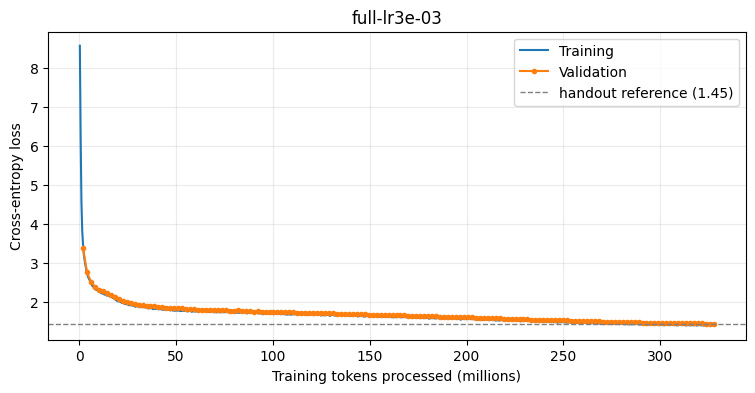

In [ ]:
if MODE == "train":
    fig, ax = plt.subplots(figsize=(9, 4))
    for key, label in [("train_loss", "Training"), ("val_loss", "Validation")]:
        records = [row for row in history if key in row]
        ax.plot(
            [row["step"] * TOKENS_PER_UPDATE / 1e6 for row in records],
            [row[key] for row in records],
            label=label,
            marker="o" if key == "val_loss" else None,
            markersize=3,
        )
    reference = 1.45 if PROFILE == "full" else 2.00
    ax.axhline(reference, color="gray", linestyle="--", linewidth=1, label=f"handout reference ({reference:.2f})")
    ax.set(xlabel="Training tokens processed (millions)", ylabel="Cross-entropy loss", title=run_dir.name)
    ax.grid(alpha=0.25)
    ax.legend()
    atomic_write(run_dir / "learning_curves.png",
                 lambda path: fig.savefig(path, format="png", dpi=150, bbox_inches="tight"))
    plt.show()

## 10. Reload and generate a story

This cell loads the export from disk. In a fresh Colab session, set `MODE = "generate"` and keep `GENERATE_FROM = "drive"`. To use a downloaded copy, upload `model.pt` through Colab's Files sidebar and set `GENERATE_FROM = "local"` and `LOCAL_MODEL_PATH` in Section 1. CPU generation works without running the data cells.

At each generation step the model predicts a distribution for the next token. Temperature $\tau$ rescales the logits, $p=\operatorname{softmax}(z/\tau)$, so lower values favor likely tokens more sharply. Top-$k$ sampling restricts the choice to the $k$ highest-scoring tokens and renormalizes. Generation ends when the model emits the story delimiter or reaches the new-token limit. This implementation recomputes attention on the most recent context at each step.

<details>
<summary>Saved story from the 40M sweep at 3e-3</summary>

Once upon a time, a little robot found a blue kite. The robot was very excited to fly the kite. He wanted to use the blue kite to fly a kite.

The red robot asked his friend, the red bird, to help him. The red bird flew fast and the green kite. They went to the park to play. The red kite took the blue kite and flew high in the sky.

At the park, the red balloon floated and the blue kite went to the park. They played all day long. The red angel was very happy with her new friend. And they lived happily ever after.

</details>

In [ ]:
@torch.inference_mode()
def generate(model, tokenizer, prompt, max_new_tokens=160, temperature=0.8, top_k=40, seed=42):
    if max_new_tokens < 0 or temperature <= 0 or top_k < 1:
        raise ValueError("Use nonnegative max_new_tokens, positive temperature, and top_k >= 1.")
    eos_id = tokenizer.token_to_id(EOT)
    ids = tokenizer.encode(prompt, add_special_tokens=False).ids
    if not ids:
        raise ValueError("Enter a non-empty story prompt.")
    rng = torch.Generator(device=device).manual_seed(seed)
    for _ in range(max_new_tokens):
        recent = torch.tensor([ids[-model.config.context_length:]], dtype=torch.long, device=device)
        logits = model(recent)[0, -1].float() / temperature
        values, choices = torch.topk(logits, min(top_k, logits.numel()))
        choice = torch.multinomial(values.softmax(dim=-1), num_samples=1, generator=rng)
        token_id = choices[choice].item()
        if token_id == eos_id:
            break
        ids.append(token_id)
    return tokenizer.decode(ids)

def fetch_github_model(destination):
    if destination.exists():
        return destination
    with requests.get(GITHUB_MODEL_URL, stream=True, timeout=(30, 120)) as response:
        if response.status_code == 404:
            raise FileNotFoundError("No model.pt in the repo's CS336_Colab folder yet. Use GENERATE_FROM = \"drive\".")
        response.raise_for_status()
        atomic_write(destination, lambda path: path.write_bytes(response.content))
    return destination

if MODE == "sweep":
    finished = [row for row in summarize_sweep() if row["finished"] and row["full_validation_loss"] is not None]
    if not finished:
        raise RuntimeError("No finished sweep run to load yet.")
    best = min(finished, key=lambda row: row["full_validation_loss"])
    run_dir = run_directory("40m", best["peak_lr"])
elif MODE == "generate" and GENERATE_FROM == "github":
    run_dir = LOCAL_ROOT / "github"
    fetch_github_model(run_dir / "model.pt")
elif MODE == "generate" and GENERATE_FROM == "local":
    run_dir = LOCAL_MODEL_PATH.parent
else:
    run_dir = run_directory(PROFILE, PEAK_LR, RUN_LABEL)
MODEL_PATH = LOCAL_MODEL_PATH if MODE == "generate" and GENERATE_FROM == "local" else run_dir / "model.pt"
story_model = story_tokenizer = saved = None
if not MODEL_PATH.is_file():
    if MODE == "train":
        print("The final model will be available after the training budget is reached.")
    else:
        raise FileNotFoundError(f"{MODEL_PATH} is missing. Check the selected model source and run settings.")
else:
    story_model, story_tokenizer, saved = load_export(MODEL_PATH)
    full = saved.get("full_validation_loss")
    print(f"Loaded {saved.get('run', MODEL_PATH.parent.name)} at iteration {saved['step']:,} | "
          f"sampled validation loss {saved['validation_loss']:.3f}"
          + (f" | full validation loss {full:.3f}" if full is not None else "") + "\n")
    PROMPT = "Once upon a time, a little robot found a blue kite."
    print(generate(story_model, story_tokenizer, PROMPT))


Loaded full-lr3e-03 at iteration 40,000 | sampled validation loss 1.447 | full validation loss 1.410
,
,Once upon a time, a little robot found a blue kite. The robot was very excited. He wanted to fly the kite in the sky. He went to the garden and started to fly the kite.
,As the robot flew the kite, he saw a little girl crying. She was crying because she lost her kite. The robot wanted to help her. He had an idea. He took the kite and ran to find the kite.
,The robot found the kite stuck in a tree. He used his strong arms to shake the tree. The kite fell down, but the little girl was safe. The robot helped her get the kite down. The little girl was very happy. She hugged the robot and thanked him. They became good friends and played together every day.
,


## 11. Package the results for `CS336_Colab`

Set `PACKAGE_RESULTS = True` below after the full run to assemble a sharing folder:

| File | Contents |
| --- | --- |
| `model.pt` | FP16 weights, configuration, tokenizer, and validation results, about 46 MB |
| `metrics.json` | Run settings, training and validation history, and the full-split validation loss |
| `learning_curves.png` | The plot from section 9 |
| `samples.md` | Stories for three fixed prompts with the sampling settings and seed |
| `lr_sweep.json`, `lr_sweep.png` | The sweep comparison, if the sweep ran |

Run the cell after training or in Drive generation mode with the full run's settings. Download the files and attach `model.pt` to a GitHub Release for sharing. If you want to track the model in the repository, add it using Git from a terminal. The 46 MB export is larger than GitHub's 25 MiB browser limit for repository files. [GitHub file sizes](https://docs.github.com/en/repositories/working-with-files/managing-large-files/about-large-files-on-github) · [GitHub Releases](https://docs.github.com/en/repositories/releasing-projects-on-github/about-releases)

In [ ]:
PACKAGE_RESULTS = False

SAMPLE_PROMPTS = (
    "Once upon a time, a little robot found a blue kite.",
    "Lily wanted to bake a cake for her mom, but",
    "Tom and his dog went to the park. Suddenly,",
)
SAMPLE_SETTINGS = dict(max_new_tokens=160, temperature=0.8, top_k=40, seed=42)

def package_results():
    lines = [
        f"# Sample stories · {saved.get('run', run_dir.name)}",
        "",
        f"Iteration {saved['step']:,}"
        + (f" of {saved['total_steps']:,}" if saved.get("total_steps") else "")
        + f" · sampled validation loss {saved['validation_loss']:.4f}"
        + (f" · full validation loss {saved['full_validation_loss']:.4f}" if saved.get("full_validation_loss") is not None else ""),
        "",
        "Sampling: " + ", ".join(f"{key} = {value}" for key, value in SAMPLE_SETTINGS.items()),
        "",
    ]
    for prompt in SAMPLE_PROMPTS:
        story = generate(story_model, story_tokenizer, prompt, **SAMPLE_SETTINGS)
        lines += [f"## {prompt}", "", story.strip(), ""]
        print(story, "\n")

    upload = root / "CS336_Colab_upload"
    upload.mkdir(parents=True, exist_ok=True)
    atomic_write(upload / "samples.md", lambda path: path.write_text("\n".join(lines), encoding="utf-8"))
    for source in (MODEL_PATH, run_dir / "metrics.json", run_dir / "learning_curves.png",
                   root / "runs" / "lr_sweep.json", root / "runs" / "lr_sweep.png"):
        if source.exists():
            stage_copy(source, upload / ("model.pt" if source == MODEL_PATH else source.name))
    for path in sorted(upload.iterdir()):
        print(f"{path.name:>22}  {path.stat().st_size / 1e6:8.2f} MB")
    print(f"\nUpload folder: {upload}")

if PACKAGE_RESULTS:
    if saved is None or saved["step"] != saved.get("total_steps") or MODE == "sweep":
        print("Load the completed model in Section 10 before packaging.")
    else:
        package_results()


### Download the files

You can download `model.pt` by itself from the run folder in Drive. To download from Colab, enable the desired switch below. The ZIP requires the package assembled in Section 11.


In [ ]:
DOWNLOAD_MODEL = False
DOWNLOAD_UPLOAD_FOLDER = False

if DOWNLOAD_MODEL or DOWNLOAD_UPLOAD_FOLDER:
    from google.colab import files

    if DOWNLOAD_MODEL:
        if not MODEL_PATH.is_file():
            raise FileNotFoundError(f"Load a saved export in Section 10 first: {MODEL_PATH}")
        files.download(str(MODEL_PATH))

    if DOWNLOAD_UPLOAD_FOLDER:
        upload = root / "CS336_Colab_upload"
        if not (upload / "model.pt").is_file():
            raise FileNotFoundError("Set PACKAGE_RESULTS = True and run Section 11 first.")
        archive = shutil.make_archive(str(LOCAL_ROOT / "CS336_Colab_upload"), "zip", upload)
        files.download(archive)

## 12. Comparing Generated Stories: 40M Sweep vs. 200M Final Run

Both stories below start from the same prompt ("Once upon a time, a little robot found a blue kite"), which makes them a useful side-by-side probe of model quality. The difference in training budget (~40M vs. ~200M tokens) shows up clearly across several dimensions.

### 12.1 Generated stories

**Saved story from the 40M sweep at `LR = 3e-3`:**

```text
Once upon a time, a little robot found a blue kite. The robot was very excited
to fly the kite. He wanted to use the blue kite to fly a kite.

The red robot asked his friend, the red bird, to help him. The red bird flew
fast and the green kite. They went to the park to play. The red kite took the
blue kite and flew high in the sky.

At the park, the red balloon floated and the blue kite went to the park. They
played all day long. The red angel was very happy with her new friend. And
they lived happily ever after.
```

**Saved story from the final 200M train at `LR = 3e-3`:**

```text
Once upon a time, a little robot found a blue kite. The robot was very excited.
He wanted to fly the kite in the sky. He went to the garden and started to fly
the kite.

As the robot flew the kite, he saw a little girl crying. She was crying because
she lost her kite. The robot wanted to help her. He had an idea. He took the
kite and ran to find the kite.

The robot found the kite stuck in a tree. He used his strong arms to shake the
tree. The kite fell down, but the little girl was safe. The robot helped her
get the kite down. The little girl was very happy. She hugged the robot and
thanked him. They became good friends and played together every day.
```

### 12.2 Entity consistency

**40M model — weak.** The story loses track of its characters almost immediately. The "little robot" becomes a "red robot," then the narrative drifts through a parade of unanchored entities: a red bird, a green kite, a red kite that "took the blue kite," a red balloon, and finally a "red angel" who was never introduced. Pronouns also shift without referents ("her new friend" — whose?).

**200M model — strong.** The cast stays fixed: one robot, one girl, one kite. Every pronoun ("he," "she," "her") resolves cleanly to the right character across the whole story. This is the single most visible improvement.

### 12.3 Narrative structure

**40M model.** There is no real plot — just a sequence of loosely kite-themed events. The ending ("lived happily ever after") is pattern-matched boilerplate attached to nothing; no problem was ever posed or resolved.

**200M model.** A complete and well-formed story arc:

- **Setup:** robot finds kite, flies it
- **Conflict:** girl is crying because she lost her kite
- **Action:** robot finds the kite stuck in a tree, shakes it loose
- **Resolution:** girl is happy, they become friends

This is the canonical TinyStories arc (problem → helpful action → friendship), and the 200M model reproduces it coherently.

### 12.4 Logical coherence

**40M model.** Contains outright contradictions and non-sequiturs: "He wanted to use the blue kite to fly a kite" (circular), "The red bird flew fast and the green kite" (ungrammatical fragment), and a kite that goes to the park on its own.

**200M model.** Causally connected throughout — the girl cries *because* she lost her kite; the robot shakes the tree *so that* the kite falls. One minor slip remains: "He took the kite and ran to find the kite" is redundant, and "the kite fell down, but the little girl was safe" implies a danger that was never established. These are small local errors rather than global breakdowns.

### 12.5 Grammar and fluency

Both models produce mostly grammatical simple sentences — expected, since even small TinyStories models learn surface fluency early. The 40M model's errors are mainly semantic (wrong subjects, dangling conjunctions), while the 200M model's sentences are nearly all well-formed. The stray `,` characters at paragraph starts in the raw 200M output (cleaned up above) look like a decoding or formatting artifact rather than a model-quality issue.

### 12.6 Summary

| Dimension | 40M sweep (3e-3) | 200M final (3e-3) |
|---|---|---|
| Character consistency | Poor — entities mutate and appear from nowhere | Strong — stable cast, clean coreference |
| Plot structure | None — event salad with a stock ending | Full arc: setup → conflict → resolution |
| Causal logic | Frequent contradictions | Mostly coherent; 1–2 minor slips |
| Grammar | Fluent but semantically broken | Fluent and semantically sound |

### 12.7 Closing remarks

The qualitative gap matches what the validation losses predict (1.6544 vs. 1.4099): the roughly 0.25-nat improvement translates into qualitatively better **long-range coherence**. The 40M model has learned local, n-gram-level fluency and story vocabulary but cannot maintain state across sentences; the 200M model tracks characters, goals, and cause-and-effect across the entire generation.

This concludes the notebook. Starting from the Assignment 1 TinyStories architecture, we
1. ran a two-round learning-rate sweep on the 40.96M-token profile,
2. selected `3e-3` as the best peak learning rate,
3. trained a fresh full-budget run over 40,000 iterations that beat the 1.45 validation-loss target (final loss 1.4099, perplexity 4.10), and
4. verified through story generation that the loss improvement corresponds to a real gain in narrative consistency and structure.

The takeaway: at this scale (22.7-million-parameter), additional training compute buys coherence — stable characters, causal plots, and complete story arcs — rather than just smoother sentences.